# 6G JSCC Dual-Architecture Demo
Human mode transmits Stable Diffusion VAE latents; machine mode transmits learned 128-D semantic vectors.


In [1]:
# Setup
import json, random, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from diffusers import AutoencoderKL
from sklearn.model_selection import train_test_split

SEED=6; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROJECT_DIR=Path.cwd()
DATA_DIR=PROJECT_DIR/'traffic_data'
RESULTS_DIR=PROJECT_DIR/'results'
CHECKPOINT_DIR=RESULTS_DIR/'checkpoints'
METRICS_DIR=RESULTS_DIR/'metrics'
FIGURE_DIR=RESULTS_DIR/'figures'

for d in (CHECKPOINT_DIR,METRICS_DIR,FIGURE_DIR): 
    d.mkdir(parents=True,exist_ok=True)
CHECKPOINT_PATH=CHECKPOINT_DIR/'machine_jscc_checkpoint.pt'
METRICS_PATH=METRICS_DIR/'evaluation_results.json'
QUALITATIVE_PATH=METRICS_DIR/'qualitative_reconstructions.npz'

SNR_LEVELS=[25,20,15,10,5,0,-5]
QUALITATIVE_SNRS=[20,10,5,0]
DIGITAL_OUTAGE_THRESHOLD_DB=5
BATCH_SIZE=8 if DEVICE.type=='cuda' else 2
TRAIN_BATCH_SIZE=16 if DEVICE.type=='cuda' else 4
HUMAN_EVAL_BATCH_SIZE=8 if DEVICE.type=='cuda' else 2

LEARNING_RATE=1e-3
MACHINE_TEST_SIZE=60
HUMAN_TEST_SIZE=20
NUM_WORKERS=0
sns.set_theme(style='whitegrid',context='paper',palette='colorblind')
plt.rcParams.update({'savefig.dpi':400,'font.family':'serif'})
print('Device:',DEVICE)

Device: cpu


In [2]:
# Dataset: 140 train, 60 machine test, and a nested 20-image human test subset
transform=transforms.Compose([transforms.Resize((512,512)),
                              transforms.ToTensor(),
                              transforms.Normalize((.5,.5,.5),(.5,.5,.5))])

dataset=datasets.ImageFolder(DATA_DIR,transform=transform)
targets=np.asarray(dataset.targets)
class_names=dataset.classes
num_classes=len(class_names)

train_indices,machine_test_indices=train_test_split(np.arange(len(dataset)),test_size=MACHINE_TEST_SIZE,stratify=targets,random_state=SEED)

_,human_test_indices=train_test_split(machine_test_indices,test_size=HUMAN_TEST_SIZE,stratify=targets[machine_test_indices],random_state=SEED+1)

train_indices=np.sort(train_indices)
machine_test_indices=np.sort(machine_test_indices)
human_test_indices=np.sort(human_test_indices)

train_loader=DataLoader(Subset(dataset,train_indices),batch_size=TRAIN_BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=DEVICE.type=='cuda')
machine_test_loader=DataLoader(Subset(dataset,machine_test_indices),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=DEVICE.type=='cuda')
human_test_loader=DataLoader(Subset(dataset,human_test_indices),batch_size=HUMAN_EVAL_BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=DEVICE.type=='cuda')

def counts(indices): 
    return {class_names[i]:int((targets[indices]==i).sum()) for i in range(num_classes)}
    
print('Classes:',class_names); print('Train:',counts(train_indices)); print('Machine test n=60:',counts(machine_test_indices)); print('Human test n=20:',counts(human_test_indices))

Classes: ['highway', 'urban']
Train: {'highway': 87, 'urban': 53}
Machine test n=60: {'highway': 37, 'urban': 23}
Human test n=20: {'highway': 12, 'urban': 8}


In [3]:
# Models and AWGN channel
vae=AutoencoderKL.from_pretrained('stabilityai/sd-vae-ft-mse').to(DEVICE).eval()
for p in vae.parameters(): 
    p.requires_grad_(False)
    
VAE_SCALING_FACTOR=vae.config.scaling_factor

class SemanticFeatureEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(3,24,5,4,2),
                               nn.BatchNorm2d(24),
                               nn.GELU(),
                               nn.Conv2d(24,48,3,2,1),
                               nn.BatchNorm2d(48),
                               nn.GELU(),
                               nn.Conv2d(48,96,3,2,1),
                               nn.BatchNorm2d(96),
                               nn.GELU(),
                               nn.Conv2d(96,128,3,2,1),
                               nn.BatchNorm2d(128),
                               nn.GELU(),
                               nn.AdaptiveAvgPool2d((1,1)))
        self.fc=nn.Linear(128,128)
        
    def forward(self,x): 
        return self.fc(self.net(x).flatten(1))

        
class MachineClassifierHead(nn.Module):
    def __init__(self,n): 
        super().__init__()
        self.fc=nn.Linear(128,n)
        
    def forward(self,x): 
        return self.fc(x)

        
def simulate_awgn_channel(tensor,snr_db):
    power=tensor.detach().pow(2).mean()
    noise=torch.randn_like(tensor)*torch.sqrt(power/(10.0**(float(snr_db)/10.0)))
    return tensor+noise
    
semantic_encoder=SemanticFeatureEncoder().to(DEVICE); machine_head=MachineClassifierHead(num_classes).to(DEVICE)
x,_=next(iter(train_loader)); x=x[:1].to(DEVICE)

with torch.inference_mode(): latent=vae.encode(x).latent_dist.mean*VAE_SCALING_FACTOR; features=semantic_encoder(x); logits=machine_head(features)

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.
C:\Users\Harshal\ML_Python\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


In [4]:
# Resumable AWGN-augmented machine training. Set ADDITIONAL_EPOCHS=0 to evaluate saved weights only.
optimizer=torch.optim.AdamW(list(semantic_encoder.parameters()) + list(machine_head.parameters()), lr=LEARNING_RATE,weight_decay=1e-4)
criterion=nn.CrossEntropyLoss()
history=[]
completed=0

if CHECKPOINT_PATH.exists():
    try: 
        ckpt=torch.load(CHECKPOINT_PATH,map_location=DEVICE,weights_only=False)
        
    except TypeError: 
        ckpt=torch.load(CHECKPOINT_PATH,map_location=DEVICE)
    split=ckpt.get('split_indices',{})
    valid=(len(split.get('train',[]))==140 and len(split.get('machine_test',[]))==60 and len(split.get('human_test',[]))==20 and ckpt.get('class_names')==class_names)
    
    if valid:
        semantic_encoder.load_state_dict(ckpt['semantic_encoder'])
        machine_head.load_state_dict(ckpt['machine_head'])
        optimizer.load_state_dict(ckpt['optimizer'])
        history=ckpt.get('history',[])
        completed=int(ckpt.get('completed_epochs',0))
        print('Resumed checkpoint at epoch',completed)
    else: 
        print('Ignoring incompatible checkpoint split.')
        
ADDITIONAL_EPOCHS=0 if completed else 20
for epoch in range(completed+1,completed+ADDITIONAL_EPOCHS+1):
    semantic_encoder.train()
    machine_head.train()
    loss_sum=correct=total=0
    for images,labels in train_loader:
        images,labels=images.to(DEVICE),labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits=machine_head(simulate_awgn_channel(semantic_encoder(images),random.choice(SNR_LEVELS)))
        loss=criterion(logits,labels)
        loss.backward()
        optimizer.step()
        loss_sum+=loss.item()*len(labels)
        correct+=(logits.argmax(1)==labels).sum().item()
        total+=len(labels)
        
    record={'epoch':epoch,'loss':loss_sum/total,'accuracy':100*correct/total}
    history.append(record)
    state={'completed_epochs':epoch,'semantic_encoder':semantic_encoder.state_dict(),'machine_head':machine_head.state_dict(),'optimizer':optimizer.state_dict(),'history':history,'class_names':class_names,'split_indices':{'train':train_indices.tolist(),'machine_test':machine_test_indices.tolist(),'human_test':human_test_indices.tolist()}}
    tmp=CHECKPOINT_PATH.with_suffix('.tmp')
    torch.save(state,tmp)
    tmp.replace(CHECKPOINT_PATH)
    print(record)
    
print('Checkpoint:',CHECKPOINT_PATH)

Resumed checkpoint at epoch 80
Checkpoint: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\checkpoints\machine_jscc_checkpoint.pt


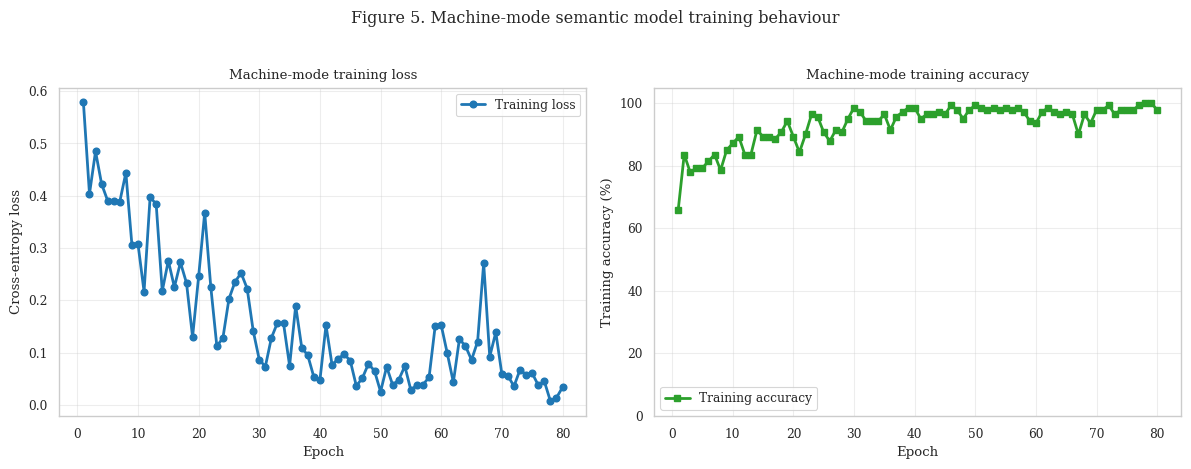

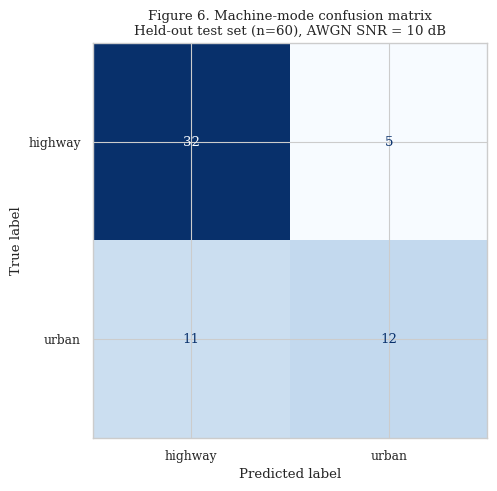

Confusion-matrix accuracy at 10 dB: 73.33%


In [5]:
# Machine-mode training curves and confusion matrix.
# Run after loading/training the machine model and defining machine_test_loader.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

CONFUSION_MATRIX_SNR_DB = 10  # Evaluate the machine model at this channel SNR.

@torch.inference_mode()
def collect_machine_predictions(snr_db):
    semantic_encoder.eval()
    machine_head.eval()

    true_labels = []
    predicted_labels = []

    for images, labels in machine_test_loader:
        images = images.to(DEVICE, non_blocking=True)

        features = semantic_encoder(images)
        noisy_features = simulate_awgn_channel(features, snr_db)
        logits = machine_head(noisy_features)

        true_labels.extend(labels.numpy())
        predicted_labels.extend(logits.argmax(dim=1).cpu().numpy())

    return np.asarray(true_labels), np.asarray(predicted_labels)

# ---- Figure 5: Training loss and training accuracy ----
epochs = [item["epoch"] for item in history]
losses = [item["loss"] for item in history]
train_accuracies = [item["accuracy"] for item in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    epochs,
    losses,
    marker="o",
    linewidth=2.0,
    color="tab:blue",
    label="Training loss",
)
axes[0].set(
    xlabel="Epoch",
    ylabel="Cross-entropy loss",
    title="Machine-mode training loss",
)
axes[0].grid(True, alpha=0.35)
axes[0].legend()

axes[1].plot(
    epochs,
    train_accuracies,
    marker="s",
    linewidth=2.0,
    color="tab:green",
    label="Training accuracy",
)
axes[1].set(
    xlabel="Epoch",
    ylabel="Training accuracy (%)",
    title="Machine-mode training accuracy",
    ylim=(0, 105),
)
axes[1].grid(True, alpha=0.35)
axes[1].legend()

fig.suptitle("Figure 5. Machine-mode semantic model training behaviour", y=1.03)
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure5_machine_training_curves.png",
    dpi=400,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "figure5_machine_training_curves.pdf",
    bbox_inches="tight",
)
plt.show()

# ---- Figure 6: Held-out machine-mode confusion matrix ----
y_true, y_pred = collect_machine_predictions(CONFUSION_MATRIX_SNR_DB)

matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
)

fig, ax = plt.subplots(figsize=(6, 5))

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names,
)
display.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d",
)

ax.set_title(
    f"Figure 6. Machine-mode confusion matrix\n"
    f"Held-out test set (n=60), AWGN SNR = {CONFUSION_MATRIX_SNR_DB} dB"
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / f"figure6_confusion_matrix_{CONFUSION_MATRIX_SNR_DB}db.png",
    dpi=400,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / f"figure6_confusion_matrix_{CONFUSION_MATRIX_SNR_DB}db.pdf",
    bbox_inches="tight",
)
plt.show()

print(
    f"Confusion-matrix accuracy at {CONFUSION_MATRIX_SNR_DB} dB: "
    f"{100 * (y_true == y_pred).mean():.2f}%"
)

In [6]:
# Cached evaluation: VAE encoding happens once for 20 images; semantic extraction once for 60 images.
def display(x): 
    return ((x+1)/2).clamp(0,1)
    
@torch.inference_mode()
def human_cache():
    ims=[]; lats=[]
    for im,_ in human_test_loader:
        im=im.to(DEVICE)
        ims.append(im.cpu())
        lats.append((vae.encode(im).latent_dist.mean*VAE_SCALING_FACTOR).cpu())
    return torch.cat(ims),torch.cat(lats)
    
@torch.inference_mode()
def machine_cache():
    fs=[]
    ys=[]
    semantic_encoder.eval()
    
    for im,y in machine_test_loader: 
        fs.append(semantic_encoder(im.to(DEVICE)).cpu()); ys.append(y)
        
    return torch.cat(fs),torch.cat(ys)
    
himages,hlatents=human_cache()
mfeatures,mlabels=machine_cache()

@torch.inference_mode()
def human_metrics(snr):
    ms=[]
    for i in range(0,20,HUMAN_EVAL_BATCH_SIZE):
        im=himages[i:i+HUMAN_EVAL_BATCH_SIZE].to(DEVICE)
        la=hlatents[i:i+HUMAN_EVAL_BATCH_SIZE].to(DEVICE)
        rec=vae.decode(simulate_awgn_channel(la,snr)/VAE_SCALING_FACTOR).sample
        ms.append((display(im)-display(rec)).pow(2).flatten(1).mean(1).cpu())
    mse=torch.cat(ms)
    return mse.mean().item(),(-10*torch.log10(mse.clamp_min(1e-12))).mean().item()
    
@torch.inference_mode()
def machine_accuracy(snr):
    correct=0
    for i in range(0,60,BATCH_SIZE):
        f=mfeatures[i:i+BATCH_SIZE].to(DEVICE)
        y=mlabels[i:i+BATCH_SIZE].to(DEVICE)
        correct+=(machine_head(simulate_awgn_channel(f,snr)).argmax(1)==y).sum().item()
    return 100*correct/60
    
results={'snr_db':[],'human_mse':[],'human_psnr_db':[],'machine_accuracy_pct':[]}
for snr in SNR_LEVELS:
    mse,psnr=human_metrics(snr)
    acc=machine_accuracy(snr)
    results['snr_db'].append(snr)
    results['human_mse'].append(mse)
    results['human_psnr_db'].append(psnr)
    results['machine_accuracy_pct'].append(acc)
    print(snr,mse,psnr,acc)
    
q={'original':display(himages[:1]).squeeze(0).permute(1,2,0).numpy()}
for snr in QUALITATIVE_SNRS:
    rec=vae.decode(simulate_awgn_channel(hlatents[:1].to(DEVICE),snr)/VAE_SCALING_FACTOR).sample
    q[f'reconstruction_{snr}db']=display(rec).squeeze(0).permute(1,2,0).cpu().numpy()
np.savez_compressed(QUALITATIVE_PATH,**q)

25 0.002462230157107115 26.333023071289062 71.66666666666667
20 0.0028185637202113867 25.72251319885254 71.66666666666667
15 0.003946606069803238 24.21904945373535 71.66666666666667
10 0.007725820876657963 21.227109909057617 71.66666666666667
5 0.022854860872030258 16.459917068481445 71.66666666666667
0 0.0684807300567627 11.661332130432129 73.33333333333333
-5 0.1298641711473465 8.869073867797852 75.0


In [7]:
# Bandwidth results and persistent metrics
payloads={'Raw image':512*512*3,'Human mode':4*64*64,'Machine mode':128}
raw,human,machine=payloads.values()

bandwidth={'payload_values':payloads,
           'payload_bytes':{k:v*4 for k,v in payloads.items()},
           'comparisons':{'raw_to_human':{'reduction_pct':100*(1-human/raw),
                                          'compression_ratio':raw/human},
                          'raw_to_machine':{'reduction_pct':100*(1-machine/raw),
                                            'compression_ratio':raw/machine},
                          'human_to_machine':{'reduction_pct':100*(1-machine/human),
                                              'compression_ratio':human/machine}}}


for name,v in payloads.items(): 
    print(name,v,'float32 values,',v*4,'bytes')
    
print('Raw→Human:',bandwidth['comparisons']['raw_to_human'])
print('Raw→Machine:',bandwidth['comparisons']['raw_to_machine'])
print('Human→Machine:',bandwidth['comparisons']['human_to_machine'])

chance=100/num_classes
digital=[100.0 if s>=DIGITAL_OUTAGE_THRESHOLD_DB else chance for s in SNR_LEVELS]
saved={'class_names':class_names,
       'human_test_images':20,
       'machine_test_images':60,
       'snr_metrics':results,
       'bandwidth':bandwidth,
       'digital_baseline':{'outage_threshold_db':DIGITAL_OUTAGE_THRESHOLD_DB,'accuracy_pct':digital}}

with open(METRICS_PATH,'w',encoding='utf-8') as f: 
    json.dump(saved,f,indent=2)
    
print('Saved metrics:',METRICS_PATH)

Raw image 786432 float32 values, 3145728 bytes
Human mode 16384 float32 values, 65536 bytes
Machine mode 128 float32 values, 512 bytes
Raw→Human: {'reduction_pct': 97.91666666666666, 'compression_ratio': 48.0}
Raw→Machine: {'reduction_pct': 99.98372395833334, 'compression_ratio': 6144.0}
Human→Machine: {'reduction_pct': 99.21875, 'compression_ratio': 128.0}
Saved metrics: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\metrics\evaluation_results.json


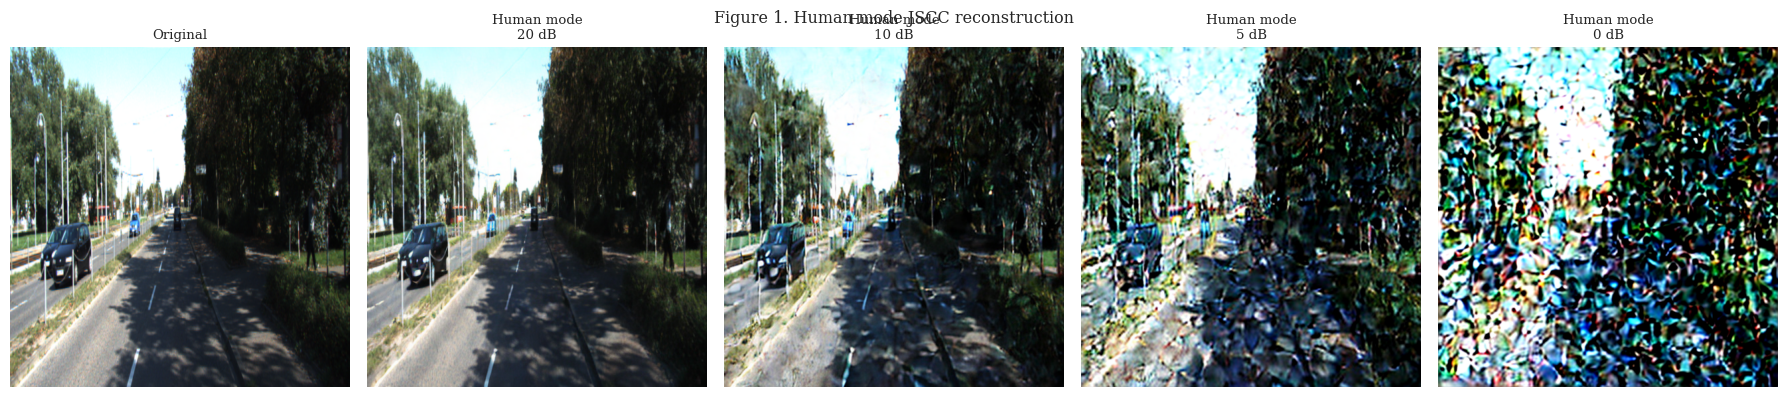

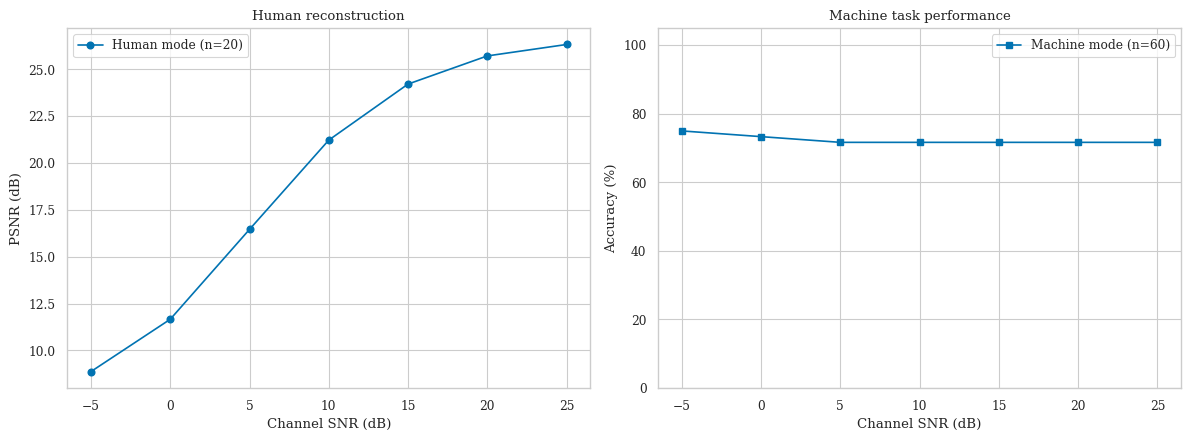

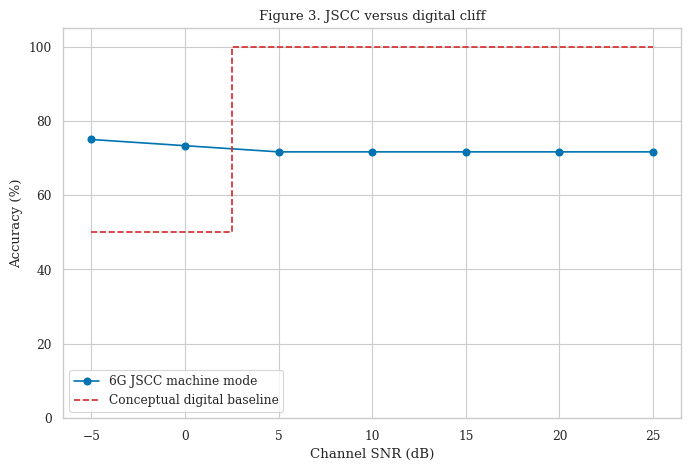

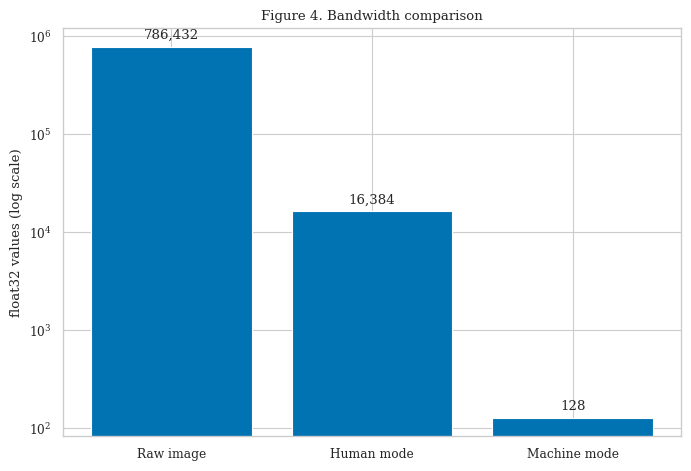

In [8]:
# Plot-only cell: later, run this cell alone after loading saved JSON/NPZ.
with open(METRICS_PATH,encoding='utf-8') as f: 
    saved=json.load(f)

q=np.load(QUALITATIVE_PATH)
r=saved['snr_metrics']
order=np.argsort(r['snr_db'])
snr=np.asarray(r['snr_db'])[order]
psnr=np.asarray(r['human_psnr_db'])[order]
acc=np.asarray(r['machine_accuracy_pct'])[order]

def save(fig,name): 
    fig.savefig(FIGURE_DIR/(name+'.png'),dpi=400,bbox_inches='tight')
    fig.savefig(FIGURE_DIR/(name+'.pdf'),bbox_inches='tight')
    
fig,ax=plt.subplots(1,5,figsize=(18,4))
ax[0].imshow(q['original'])
ax[0].set_title('Original')
ax[0].axis('off')

for a,s in zip(ax[1:],QUALITATIVE_SNRS): 
    a.imshow(q[f'reconstruction_{s}db'])
    a.set_title(f'Human mode\n{s} dB')
    a.axis('off')
    
fig.suptitle('Figure 1. Human-mode JSCC reconstruction')
plt.tight_layout()
save(fig,'figure1_qualitative_human_reconstructions')
plt.show()

fig,ax=plt.subplots(1,2,figsize=(12,4.5))
ax[0].plot(snr,psnr,'o-',label='Human mode (n=20)')
ax[0].set(xlabel='Channel SNR (dB)',ylabel='PSNR (dB)',title='Human reconstruction')
ax[0].legend(); ax[1].plot(snr,acc,'s-',label='Machine mode (n=60)')
ax[1].set(xlabel='Channel SNR (dB)',ylabel='Accuracy (%)',title='Machine task performance',ylim=(0,105))
ax[1].legend(); plt.tight_layout()
save(fig,'figure2_performance_vs_snr')
plt.show()

digital=np.asarray(saved['digital_baseline']['accuracy_pct'])[order]
fig,ax=plt.subplots(figsize=(7,4.8))
ax.plot(snr,acc,'o-',label='6G JSCC machine mode')
ax.step(snr,digital,where='mid',ls='--',color='tab:red',label='Conceptual digital baseline')
ax.set(xlabel='Channel SNR (dB)',ylabel='Accuracy (%)',title='Figure 3. JSCC versus digital cliff',ylim=(0,105)); ax.legend()
plt.tight_layout()
save(fig,'figure3_jscc_vs_digital_cliff_effect')
plt.show()

p=saved['bandwidth']['payload_values']
fig,ax=plt.subplots(figsize=(7,4.8))
bars=ax.bar(p.keys(),p.values())
ax.set_yscale('log')
ax.set(ylabel='float32 values (log scale)',title='Figure 4. Bandwidth comparison')
[ax.text(b.get_x()+b.get_width()/2,v*1.2,f'{v:,}',ha='center') for b,v in zip(bars,p.values())]
plt.tight_layout()
save(fig,'figure4_bandwidth_comparison')
plt.show()

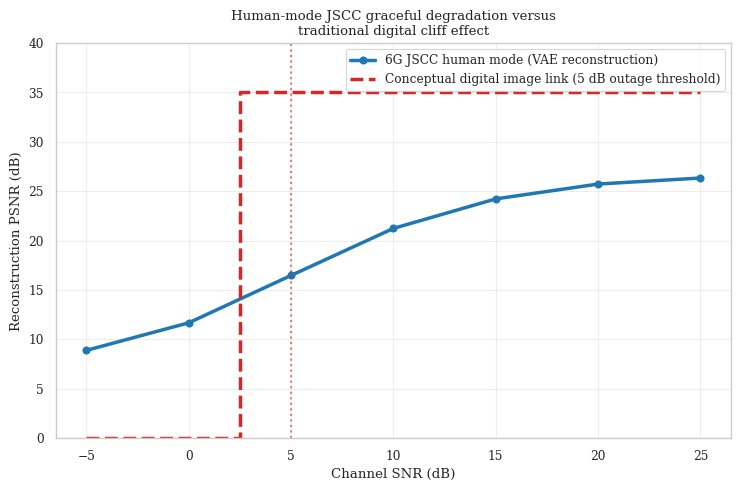

Saved: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\figures\figure_human_jscc_vs_digital_cliff_effect.png
Saved: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\figures\figure_human_jscc_vs_digital_cliff_effect.pdf


In [9]:
# Human-mode JSCC reconstruction quality versus conceptual digital cliff effect.
# Uses PSNR as the human-mode quality metric.

with open(METRICS_PATH, "r", encoding="utf-8") as file:
    saved_results = json.load(file)

metrics = saved_results["snr_metrics"]

plot_order = np.argsort(metrics["snr_db"])
plot_snr = np.asarray(metrics["snr_db"])[plot_order]
human_psnr = np.asarray(metrics["human_psnr_db"])[plot_order]

# Conceptual digital image-link baseline:
# above threshold: high-fidelity decoded image; below threshold: packet outage.
DIGITAL_HUMAN_PSNR_DB = 35.0
DIGITAL_OUTAGE_PSNR_DB = 0.0
DIGITAL_THRESHOLD_DB = saved_results["digital_baseline"]["outage_threshold_db"]

digital_human_psnr = np.asarray([
    DIGITAL_HUMAN_PSNR_DB if snr >= DIGITAL_THRESHOLD_DB
    else DIGITAL_OUTAGE_PSNR_DB
    for snr in plot_snr
])

fig, ax = plt.subplots(figsize=(7.5, 5))

ax.plot(
    plot_snr,
    human_psnr,
    marker="o",
    linewidth=2.5,
    color="tab:blue",
    label="6G JSCC human mode (VAE reconstruction)",
)

ax.step(
    plot_snr,
    digital_human_psnr,
    where="mid",
    linewidth=2.5,
    linestyle="--",
    color="tab:red",
    label=(
        "Conceptual digital image link "
        f"({DIGITAL_THRESHOLD_DB} dB outage threshold)"
    ),
)

ax.axvline(
    DIGITAL_THRESHOLD_DB,
    color="tab:red",
    linestyle=":",
    alpha=0.6,
    linewidth=1.5,
)

ax.set(
    xlabel="Channel SNR (dB)",
    ylabel="Reconstruction PSNR (dB)",
    title=(
        "Human-mode JSCC graceful degradation versus\n"
        "traditional digital cliff effect"
    ),
    ylim=(0, max(DIGITAL_HUMAN_PSNR_DB + 5, human_psnr.max() + 5)),
)

ax.grid(True, alpha=0.35)
ax.legend(loc="best", frameon=True)

plt.tight_layout()

output_png = FIGURE_DIR / "figure_human_jscc_vs_digital_cliff_effect.png"
output_pdf = FIGURE_DIR / "figure_human_jscc_vs_digital_cliff_effect.pdf"

fig.savefig(output_png, dpi=400, bbox_inches="tight")
fig.savefig(output_pdf, bbox_inches="tight")

plt.show()

print(f"Saved: {output_png}")
print(f"Saved: {output_pdf}")

In [10]:
# Traditional digital image receiver: JPEG source coding + black-frame outage.
# Run after the human-mode evaluation cell, where `himages`, `results`,
# `METRICS_PATH`, `QUALITATIVE_PATH`, and `FIGURE_DIR` already exist.

from io import BytesIO
from PIL import Image
import json

JPEG_QUALITY = 95
DIGITAL_OUTAGE_THRESHOLD_DB = 5

def tensor_to_jpeg_receiver_image(image_01, quality=JPEG_QUALITY):
    """JPEG encode/decode one [3, H, W] image in [0, 1]."""
    image_uint8 = (
        image_01.clamp(0, 1)
        .mul(255)
        .round()
        .byte()
        .permute(1, 2, 0)
        .cpu()
        .numpy()
    )

    buffer = BytesIO()
    Image.fromarray(image_uint8, mode="RGB").save(
        buffer,
        format="JPEG",
        quality=quality,
        optimize=True,
    )
    buffer.seek(0)

    with Image.open(buffer) as decoded_image:
        decoded_array = np.asarray(
            decoded_image.convert("RGB"),
            dtype=np.float32,
        ).copy()

    return torch.from_numpy(decoded_array).permute(2, 0, 1) / 255.0

In [11]:
def simulate_traditional_digital_receiver(images_normalized, snr_db):
    """
    Traditional separation-based receiver:
    - At/above threshold: JPEG image is decoded successfully.
    - Below threshold: packet decoding fails and receiver displays a black frame.
    """
    reference_images = ((images_normalized + 1.0) / 2.0).clamp(0, 1)

    if snr_db < DIGITAL_OUTAGE_THRESHOLD_DB:
        return torch.zeros_like(reference_images)

    decoded_images = [
        tensor_to_jpeg_receiver_image(image)
        for image in reference_images
    ]
    return torch.stack(decoded_images, dim=0)


@torch.inference_mode()
def traditional_digital_metrics(snr_db):
    total_mse = 0.0
    total_psnr = 0.0
    total_images = 0

    for start in range(0, len(himages), HUMAN_EVAL_BATCH_SIZE):
        stop = start + HUMAN_EVAL_BATCH_SIZE

        original_normalized = himages[start:stop]
        original_01 = ((original_normalized + 1.0) / 2.0).clamp(0, 1)

        received_01 = simulate_traditional_digital_receiver(
            original_normalized,
            snr_db,
        )

        per_image_mse = (
            original_01 - received_01
        ).pow(2).flatten(1).mean(1)

        total_mse += per_image_mse.sum().item()
        total_psnr += (
            -10.0 * torch.log10(per_image_mse.clamp_min(1e-12))
        ).sum().item()
        total_images += original_normalized.size(0)

    return total_mse / total_images, total_psnr / total_images

In [12]:
# Calculate traditional digital receiver PSNR/MSE over the same 20 human-test images.
traditional_mse = []
traditional_psnr_db = []
traditional_receiver_state = []

for snr_db in SNR_LEVELS:
    mse, psnr = traditional_digital_metrics(snr_db)

    traditional_mse.append(float(mse))
    traditional_psnr_db.append(float(psnr))

    state = (
        f"JPEG decoded (quality={JPEG_QUALITY})"
        if snr_db >= DIGITAL_OUTAGE_THRESHOLD_DB
        else "Digital outage: black receiver frame"
    )
    traditional_receiver_state.append(state)

    print(
        f"SNR {snr_db:>3} dB | "
        f"Traditional digital MSE: {mse:.6f} | "
        f"Traditional digital PSNR: {psnr:.2f} dB | "
        f"{state}"
    )

assert len(traditional_psnr_db) == len(SNR_LEVELS)

# Save representative traditional receiver images for the qualitative SNR values.
existing_qualitative = {}
if QUALITATIVE_PATH.exists():
    with np.load(QUALITATIVE_PATH) as saved_qualitative:
        existing_qualitative = {
            key: saved_qualitative[key]
            for key in saved_qualitative.files
        }

for snr_db in QUALITATIVE_SNRS:
    receiver_image = simulate_traditional_digital_receiver(
        himages[:1],
        snr_db,
    )
    existing_qualitative[f"traditional_receiver_{snr_db}db"] = (
        receiver_image[0].permute(1, 2, 0).numpy()
    )

np.savez_compressed(QUALITATIVE_PATH, **existing_qualitative)

SNR  25 dB | Traditional digital MSE: 0.000345 | Traditional digital PSNR: 34.74 dB | JPEG decoded (quality=95)
SNR  20 dB | Traditional digital MSE: 0.000345 | Traditional digital PSNR: 34.74 dB | JPEG decoded (quality=95)
SNR  15 dB | Traditional digital MSE: 0.000345 | Traditional digital PSNR: 34.74 dB | JPEG decoded (quality=95)
SNR  10 dB | Traditional digital MSE: 0.000345 | Traditional digital PSNR: 34.74 dB | JPEG decoded (quality=95)
SNR   5 dB | Traditional digital MSE: 0.000345 | Traditional digital PSNR: 34.74 dB | JPEG decoded (quality=95)
SNR   0 dB | Traditional digital MSE: 0.246286 | Traditional digital PSNR: 6.20 dB | Digital outage: black receiver frame
SNR  -5 dB | Traditional digital MSE: 0.246286 | Traditional digital PSNR: 6.20 dB | Digital outage: black receiver frame


In [13]:
# Update persistent experiment metrics.
with open(METRICS_PATH, "r", encoding="utf-8") as file:
    saved_results = json.load(file)

saved_results["traditional_digital_image_link"] = {
    "source_codec": "JPEG",
    "jpeg_quality": JPEG_QUALITY,
    "outage_threshold_db": DIGITAL_OUTAGE_THRESHOLD_DB,
    "receiver_behavior_below_threshold": "black frame",
    "human_test_images": len(himages),
    "snr_db": [int(snr) for snr in SNR_LEVELS],
    "mse": traditional_mse,
    "psnr_db": traditional_psnr_db,
    "receiver_state": traditional_receiver_state,
}

with open(METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(saved_results, file, indent=2)

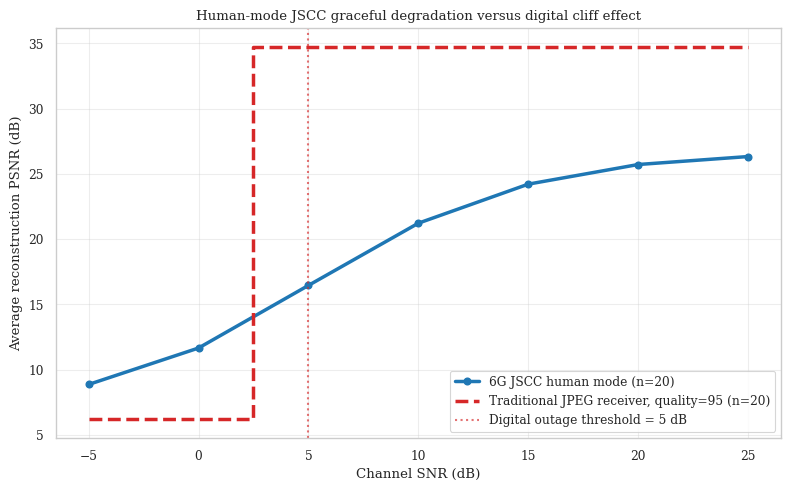

Saved metrics: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\metrics\evaluation_results.json
Saved qualitative receiver images: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\metrics\qualitative_reconstructions.npz
Saved figure: D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\results\figures\figure_human_jscc_vs_traditional_digital_psnr.png


In [14]:
# Plot measured traditional-digital PSNR against human-mode JSCC PSNR.
plot_order = np.argsort(results["snr_db"])
plot_snr = np.asarray(results["snr_db"])[plot_order]
human_psnr = np.asarray(results["human_psnr_db"])[plot_order]
digital_psnr = np.asarray(traditional_psnr_db)[plot_order]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    plot_snr,
    human_psnr,
    marker="o",
    linewidth=2.5,
    color="tab:blue",
    label="6G JSCC human mode (n=20)",
)

ax.step(
    plot_snr,
    digital_psnr,
    where="mid",
    linewidth=2.5,
    linestyle="--",
    color="tab:red",
    label=f"Traditional JPEG receiver, quality={JPEG_QUALITY} (n=20)",
)

ax.axvline(
    DIGITAL_OUTAGE_THRESHOLD_DB,
    color="tab:red",
    linestyle=":",
    linewidth=1.5,
    alpha=0.65,
    label=f"Digital outage threshold = {DIGITAL_OUTAGE_THRESHOLD_DB} dB",
)

ax.set(
    xlabel="Channel SNR (dB)",
    ylabel="Average reconstruction PSNR (dB)",
    title="Human-mode JSCC graceful degradation versus digital cliff effect",
)

ax.grid(True, alpha=0.35)
ax.legend(loc="best", frameon=True)

plt.tight_layout()

output_png = FIGURE_DIR / "figure_human_jscc_vs_traditional_digital_psnr.png"
output_pdf = FIGURE_DIR / "figure_human_jscc_vs_traditional_digital_psnr.pdf"

fig.savefig(output_png, dpi=400, bbox_inches="tight")
fig.savefig(output_pdf, bbox_inches="tight")

plt.show()

print(f"Saved metrics: {METRICS_PATH}")
print(f"Saved qualitative receiver images: {QUALITATIVE_PATH}")
print(f"Saved figure: {output_png}")